In [1]:
# ==========================================
# DAY 5: CLASSIFICATION MODELS
# CELL 1: IMPORT LIBRARIES
# ==========================================

import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("All classification libraries imported successfully!")

All classification libraries imported successfully!


In [2]:
# ==========================================
# CELL 2: LOAD PROCESSED DATA
# ==========================================

train_path = "../data/processed/train_split.csv"
val_path = "../data/processed/val_split.csv"
test_path = "../data/processed/test_split.csv"

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)

# Convert Date into datetime, if available
for df in [train_df, val_df, test_df]:
    if "Date" in df.columns:
        df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Datasets loaded successfully!\n")

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Testing shape:", test_df.shape)

print("\nAvailable columns:")
print(train_df.columns.tolist())

print("\nTraining data sample:")
display(train_df.head())

Datasets loaded successfully!

Training shape: (47600, 28)
Validation shape: (7500, 28)
Testing shape: (7500, 28)

Available columns:
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion', 'Competitor Pricing', 'Seasonality', 'Year', 'Month', 'Day', 'DayOfWeek', 'Quarter', 'Is_Weekend', 'Units_Sold_Lag_1', 'Units_Sold_Lag_7', 'Rolling_Mean_7', 'Rolling_Std_7', 'Units_Sold_Lag_14', 'Units_Sold_Lag_28', 'Rolling_Mean_28']

Training data sample:


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,...,DayOfWeek,Quarter,Is_Weekend,Units_Sold_Lag_1,Units_Sold_Lag_7,Rolling_Mean_7,Rolling_Std_7,Units_Sold_Lag_14,Units_Sold_Lag_28,Rolling_Mean_28
0,2022-02-05,S001,P0001,Groceries,South,458.0,350.0,182.0,362.43,51.44,...,5,1,1,25.0,47.0,156.142857,124.957898,191.0,2.0,136.642857
1,2022-02-06,S001,P0001,Electronics,North,167.0,69.0,92.0,81.06,68.85,...,6,1,1,350.0,130.0,147.428571,129.141856,79.0,350.0,126.607143
2,2022-02-07,S001,P0001,Electronics,South,244.0,62.0,105.0,73.41,11.34,...,0,1,0,69.0,200.0,127.714286,130.306964,9.0,36.0,127.535714
3,2022-02-08,S001,P0001,Toys,West,140.0,12.0,48.0,15.60,67.64,...,1,1,0,62.0,279.0,89.571429,117.045372,189.0,16.0,127.392857
4,2022-02-09,S001,P0001,Groceries,South,209.0,16.0,143.0,22.37,90.55,...,2,1,0,12.0,38.0,86.428571,118.940962,49.0,104.0,124.250000


In [3]:
# ==========================================
# CELL 3: CREATE DEMAND CLASSIFICATION TARGET
# ==========================================

TARGET = "Units Sold"

if TARGET not in train_df.columns:
    raise ValueError(f"Required target column '{TARGET}' not found.")

if not pd.api.types.is_numeric_dtype(train_df[TARGET]):
    raise TypeError(f"'{TARGET}' must contain numeric sales values.")

# Learn the thresholds using training data only
q33 = train_df[TARGET].quantile(0.33)
q67 = train_df[TARGET].quantile(0.67)

print(f"Low demand upper boundary: {q33:.2f}")
print(f"Medium demand upper boundary: {q67:.2f}")

def assign_demand_class(series):
    return pd.Series(
        np.select(
            [
                series <= q33,
                (series > q33) & (series <= q67),
                series > q67
            ],
            ["Low", "Medium", "High"],
            default="Medium"
        ),
        index=series.index,
        name="Demand_Class"
    )

# Apply the same training thresholds to every split
for df in [train_df, val_df, test_df]:
    df["Demand_Class"] = assign_demand_class(df[TARGET])

print("\nTraining demand class distribution:")
display(
    train_df["Demand_Class"]
    .value_counts()
    .reindex(["Low", "Medium", "High"], fill_value=0)
    .rename("Records")
    .to_frame()
)

print("\nValidation demand class distribution:")
display(val_df["Demand_Class"].value_counts())

print("\nTest demand class distribution:")
display(test_df["Demand_Class"].value_counts())

Low demand upper boundary: 65.00
Medium demand upper boundary: 166.00

Training demand class distribution:


,Records
Demand_Class,
Low,15846
Medium,16092
High,15662



Validation demand class distribution:


Demand_Class
High      2535
Medium    2484
Low       2481
Name: count, dtype: int64


Test demand class distribution:


Demand_Class
Medium    2555
High      2522
Low       2423
Name: count, dtype: int64

In [4]:
# ==========================================
# CELL 4: PREPARE X AND y
# ==========================================

# Columns that must not be used as input features
excluded_columns = [
    "Date",
    "Units Sold",
    "Demand_Class",
    "Store ID",
    "Product ID",
    "Rolling_Mean_7",
    "Rolling_Std_7",
    "Rolling_Mean_28"
]

# Select columns that actually exist in this dataset
feature_columns = [
    col for col in train_df.columns
    if col not in excluded_columns
]

if not feature_columns:
    raise ValueError("No input features remain. Check the dataset columns.")

X_train = train_df[feature_columns].copy()
X_val = val_df.reindex(columns=feature_columns).copy()
X_test = test_df.reindex(columns=feature_columns).copy()

y_train = train_df["Demand_Class"].copy()
y_val = val_df["Demand_Class"].copy()
y_test = test_df["Demand_Class"].copy()

print("Number of input features:", len(feature_columns))
print("\nFeatures used:")
print(feature_columns)

print("\nTraining X:", X_train.shape)
print("Validation X:", X_val.shape)
print("Testing X:", X_test.shape)

print("\nTarget distribution:")
print(y_train.value_counts())

Number of input features: 21

Features used:
['Category', 'Region', 'Inventory Level', 'Units Ordered', 'Demand Forecast', 'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion', 'Competitor Pricing', 'Seasonality', 'Year', 'Month', 'Day', 'DayOfWeek', 'Quarter', 'Is_Weekend', 'Units_Sold_Lag_1', 'Units_Sold_Lag_7', 'Units_Sold_Lag_14', 'Units_Sold_Lag_28']

Training X: (47600, 21)
Validation X: (7500, 21)
Testing X: (7500, 21)

Target distribution:
Demand_Class
Medium    16092
Low       15846
High      15662
Name: count, dtype: int64


In [5]:
import sys
sys.path.append('..')
from preprocess import build_preprocessor

# Build the preprocessor using your training features
preprocessor, numeric_features, categorical_features = build_preprocessor(X_train)

Numeric features: ['Inventory Level', 'Units Ordered', 'Demand Forecast', 'Price', 'Discount', 'Holiday/Promotion', 'Competitor Pricing', 'Year', 'Month', 'Day', 'DayOfWeek', 'Quarter', 'Is_Weekend', 'Units_Sold_Lag_1', 'Units_Sold_Lag_7', 'Units_Sold_Lag_14', 'Units_Sold_Lag_28']
Categorical features: ['Category', 'Region', 'Weather Condition', 'Seasonality']

Preprocessing pipeline created successfully!


In [6]:
# ==========================================
# CELL 6: DEFINE CLASSIFIERS
# ==========================================

models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),

    "Naive Bayes": GaussianNB(),

    "SVM": SVC(
        kernel="rbf",
        C=1.0,
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        random_state=RANDOM_STATE,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        class_weight="balanced"
    )
}

trained_models = {}
validation_predictions = {}
validation_results = []

for model_name, classifier in models.items():
    print(f"\nTraining {model_name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_val)

    trained_models[model_name] = pipeline
    validation_predictions[model_name] = predictions

    result = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        )
    }

    validation_results.append(result)

    print(f"{model_name} trained successfully!")

print("\nAll five classifiers have been trained.")


Training KNN...
KNN trained successfully!

Training Naive Bayes...
Naive Bayes trained successfully!

Training SVM...
SVM trained successfully!

Training Decision Tree...
Decision Tree trained successfully!

Training Random Forest...
Random Forest trained successfully!

All five classifiers have been trained.


In [11]:
# ==========================================
# CELL 7: MODEL COMPARISON TABLE
# ==========================================

results_df = pd.DataFrame(validation_results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("\nBest model based on validation Macro F1-score:")
print(best_model_name)
print(f"Validation Macro F1-score: {results_df.iloc[0]['F1-Score']:.4f}")

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.9383,0.9384,0.9381,0.9382
1,Random Forest,0.9379,0.9390,0.9377,0.9379
2,SVM,0.9264,0.9274,0.9262,0.9266
3,Naive Bayes,0.9187,0.9188,0.9185,0.9185
4,KNN,0.6636,0.6601,0.6625,0.6611



Best model based on validation Macro F1-score:
Decision Tree
Validation Macro F1-score: 0.9382


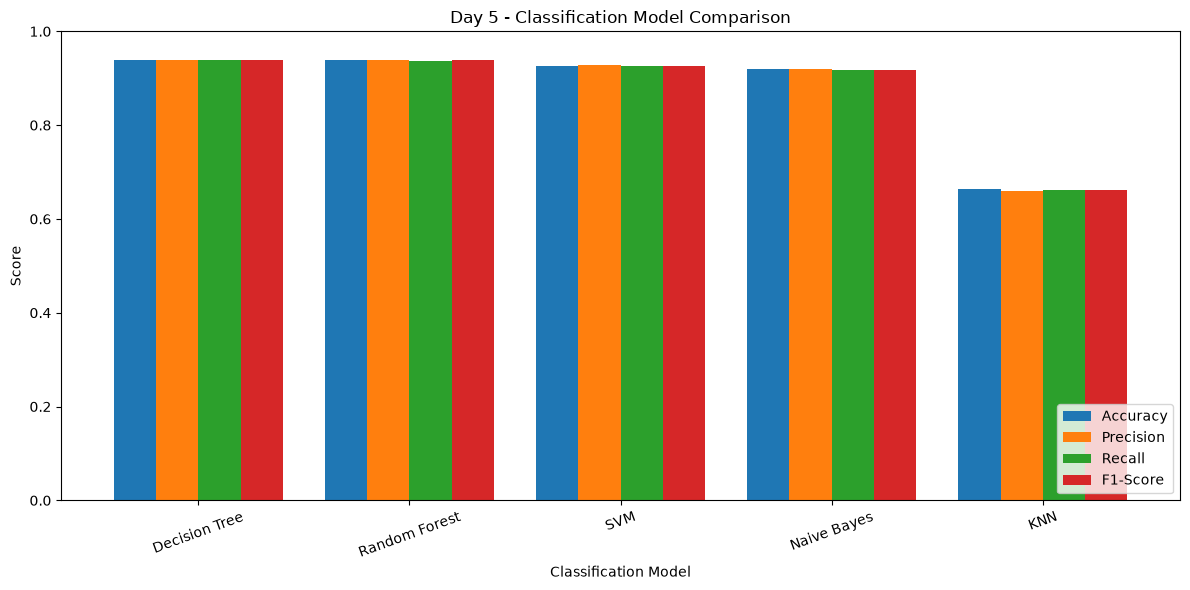

In [12]:
# ==========================================
# CELL 8: VISUALIZE MODEL PERFORMANCE
# ==========================================

metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

ax = results_df.set_index("Model")[metrics_to_plot].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.8
)

ax.set_title("Day 5 - Classification Model Comparison")
ax.set_xlabel("Classification Model")
ax.set_ylabel("Score")
ax.legend(loc="lower right")
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

Validation report: Decision Tree

              precision    recall  f1-score   support

         Low       0.94      0.93      0.94      2481
      Medium       0.90      0.92      0.91      2484
        High       0.97      0.97      0.97      2535

    accuracy                           0.94      7500
   macro avg       0.94      0.94      0.94      7500
weighted avg       0.94      0.94      0.94      7500



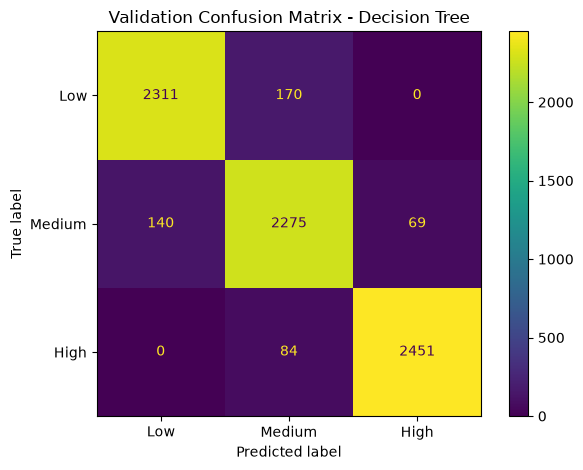

In [13]:
# ==========================================
# CELL 9: VALIDATION CLASSIFICATION REPORT
# ==========================================

class_labels = ["Low", "Medium", "High"]

val_best_preds = validation_predictions[best_model_name]

print(f"Validation report: {best_model_name}\n")

print(
    classification_report(
        y_val,
        val_best_preds,
        labels=class_labels,
        zero_division=0
    )
)

cm = confusion_matrix(
    y_val,
    val_best_preds,
    labels=class_labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
)

disp.plot(values_format="d")
plt.title(f"Validation Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()